In [1]:
!pip install optuna -q

import warnings, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score,
    brier_score_loss, roc_auc_score, confusion_matrix,
    PrecisionRecallDisplay, RocCurveDisplay, classification_report
)
from sklearn.calibration import calibration_curve
import joblib

from xgboost import XGBClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80)
SEED = 42
np.random.seed(SEED)

ROOT = Path('..')          # chạy từ thư mục notebooks/
DATA = ROOT / 'data' / 'processed'
OUT  = ROOT / 'data' / 'outputs'
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.facecolor': '#0f1117', 'axes.facecolor': '#0f1117',
    'axes.edgecolor': '#3d4058', 'grid.color': '#2a2d3e',
    'text.color': '#e0e0e0', 'axes.labelcolor': '#e0e0e0',
    'xtick.color': '#9e9e9e', 'ytick.color': '#9e9e9e',
    'figure.dpi': 120,
})
PAL = ['#7c83fd', '#fd7c83', '#7cfd9e', '#fdd97c']
print('Imports OK')


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


Imports OK


In [2]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data' / 'processed' / 'modeling_dataset.csv').exists():
    candidates = [p for p in Path.cwd().parents if (p / 'data' / 'processed' / 'modeling_dataset.csv').exists()]
    if not candidates:
        raise FileNotFoundError('Không tìm thấy data/processed/modeling_dataset.csv; mở notebook từ thư mục gốc repo.')
    PROJECT_ROOT = candidates[0]
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'modeling_dataset.csv'
OUTPUT_DIR = PROJECT_ROOT / 'artifacts' / 'modeling'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Project root:', PROJECT_ROOT)
print('Output folder:', OUTPUT_DIR)
df = pd.read_csv(DATA_PATH, parse_dates=['arrival_date', 'booking_date'])
print(f'Loaded {len(df):,} rows x {df.shape[1]} columns  from  {DATA_PATH}')
df.head(3)

Project root: c:\Users\Admin\OneDrive\Desktop\BA-Advance-Project---Group-2
Output folder: c:\Users\Admin\OneDrive\Desktop\BA-Advance-Project---Group-2\artifacts\modeling
Loaded 78,892 rows x 61 columns  from  c:\Users\Admin\OneDrive\Desktop\BA-Advance-Project---Group-2\data\processed\modeling_dataset.csv


,booking_id,population,split,is_canceled,arrival_date,booking_date,is_duplicate,gross_value,syn_net_booking_value,lead_time,lead_time_log,is_last_minute,is_far_ahead,booking_month,booking_dow,arrival_month_sin,arrival_month_cos,arrival_week_sin,arrival_week_cos,is_weekend_arrival,is_high_season,total_nights,stays_in_weekend_nights,stays_in_week_nights,weekend_night_share,is_long_stay,adults,children,babies,total_guests,has_children,is_solo,adr_clean,adr_vs_ref,adr_per_guest,is_free_rate,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,prev_bookings_total,prev_cancel_ratio,has_prev_cancel,has_agent,has_company,drv_otb_rooms_at_booking,days_in_waiting_list,has_waiting_list,total_of_special_requests,has_special_requests,market_segment,distribution_channel,customer_type,reserved_room_type,meal,agent_top,arrival_dow,is_non_refund,is_group_block,dup_group_size,dup_group_size_log,deposit_type
0,1,individual,train,0,2015-07-01,2015-06-25,0,0.0,-54.68,6,1.9459,1,0,6,3,-0.5,-0.866,-0.0592,-0.9982,0,1,2,0,2,0.0,0,1,0,0,1,0,1,0.0,0.0000,0.00,1,0,0,0,0,0.0,0,1,0,65,0,0,0,0,Offline TA/TO,TA/TO,Transient,A,HB,6,Wednesday,0,0,1,0.6931,No Deposit
1,2,individual,train,1,2015-07-01,2015-04-04,0,306.0,148.52,88,4.4886,0,0,4,5,-0.5,-0.866,-0.0592,-0.9982,0,1,4,0,4,0.0,0,2,0,0,2,0,0,76.5,0.8793,38.25,0,0,0,0,0,0.0,0,1,0,76,0,0,1,1,Online TA,TA/TO,Transient,A,BB,9,Wednesday,0,0,1,0.6931,No Deposit
2,3,individual,train,1,2015-07-01,2015-04-27,0,272.0,111.92,65,4.1897,0,0,4,0,-0.5,-0.866,-0.0592,-0.9982,0,1,4,0,4,0.0,0,1,0,0,1,0,1,68.0,0.7816,68.00,0,0,0,0,0,0.0,0,1,0,77,0,0,1,1,Online TA,TA/TO,Transient,A,BB,9,Wednesday,0,0,1,0.6931,No Deposit


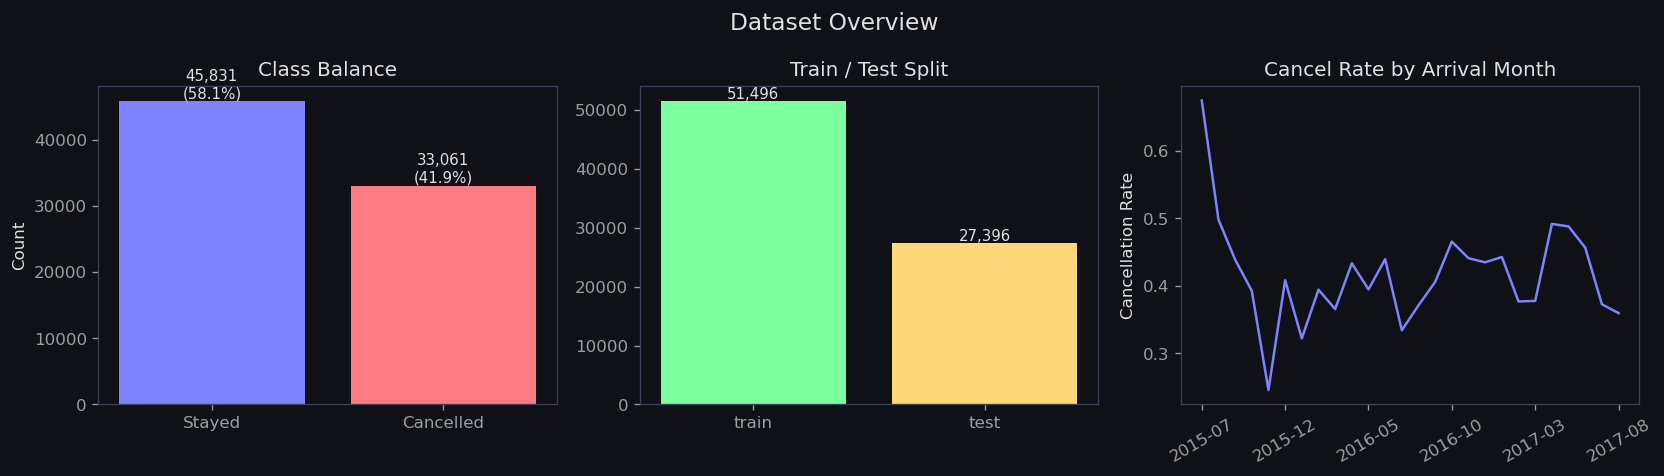

Overall cancel rate: 41.91%
       cancel_rate
split             
test      0.426230
train     0.415256


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Dataset Overview', color='#e0e0e0', fontsize=14)

vc = df.is_canceled.value_counts()
axes[0].bar(['Stayed', 'Cancelled'], [vc[0], vc[1]], color=PAL[:2])
axes[0].set_title('Class Balance'); axes[0].set_ylabel('Count')
for i, v in enumerate([vc[0], vc[1]]):
    axes[0].text(i, v + 500, f'{v:,}\n({v/len(df):.1%})', ha='center', fontsize=9)

split_vc = df.split.value_counts()
axes[1].bar(split_vc.index, split_vc.values, color=PAL[2:])
axes[1].set_title('Train / Test Split')
for i, (s, v) in enumerate(split_vc.items()):
    axes[1].text(i, v + 500, f'{v:,}', ha='center', fontsize=9)

monthly = df.groupby(df.arrival_date.dt.to_period('M')).is_canceled.mean().reset_index()
monthly.columns = ['month', 'cancel_rate']
monthly['month'] = monthly['month'].astype(str)
axes[2].plot(monthly.month, monthly.cancel_rate, color=PAL[0], linewidth=1.5)
axes[2].set_title('Cancel Rate by Arrival Month')
axes[2].set_ylabel('Cancellation Rate')
axes[2].xaxis.set_major_locator(mticker.MaxNLocator(6))
plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

print(f'Overall cancel rate: {df.is_canceled.mean():.2%}')
print(df.groupby('split').is_canceled.mean().rename('cancel_rate').to_frame())

In [4]:
issues = []

n_dup_id = df.booking_id.duplicated().sum()
issues.append({'check': 'duplicate booking_id', 'n': int(n_dup_id),
               'status': 'FAIL' if n_dup_id > 0 else 'OK'})

n_dup_row = df.duplicated(keep=False).sum()
issues.append({'check': 'exact-row duplicates', 'n': int(n_dup_row),
               'status': 'WARN' if n_dup_row > 0 else 'OK'})

LEAKAGE_CANDIDATES = ['reservation_status', 'reservation_status_date', 'assigned_room_type']
found_leakage = [c for c in LEAKAGE_CANDIDATES if c in df.columns]
issues.append({'check': 'post-cancellation leakage columns', 'n': len(found_leakage),
               'detail': str(found_leakage),
               'status': 'FAIL' if found_leakage else 'OK'})

bad_dates = (df.booking_date > df.arrival_date).sum()
issues.append({'check': 'booking_date > arrival_date', 'n': int(bad_dates),
               'status': 'WARN' if bad_dates > 0 else 'OK'})

TRAIN_END = pd.Timestamp('2016-12-31')
max_train = df.loc[df.split == 'train', 'arrival_date'].max()
min_test  = df.loc[df.split == 'test',  'arrival_date'].min()
overlap = max_train >= min_test
issues.append({'check': 'train/test date overlap', 'n': int(overlap),
               'detail': f'max_train={max_train.date()} | min_test={min_test.date()}',
               'status': 'FAIL' if overlap else 'OK'})

syn_cols = [c for c in df.columns if c.startswith('syn_')]
issues.append({'check': 'syn_ columns present', 'n': len(syn_cols),
               'detail': str(syn_cols), 'status': 'INFO'})

audit_df = pd.DataFrame(issues)
display(audit_df)

if any(i['status'] == 'FAIL' for i in issues):
    print('CRITICAL issues found — review before proceeding!')
else:
    print('No critical leakage or split issues found.')

,check,n,status,detail
0,duplicate booking_id,0,OK,NaN
1,exact-row duplicates,0,OK,NaN
2,post-cancellation leakage columns,0,OK,[]
3,booking_date > arrival_date,0,OK,NaN
4,train/test date overlap,0,OK,max_train=2016-12-31 | min_test=2017-01-01
5,syn_ columns present,1,INFO,['syn_net_booking_value']


No critical leakage or split issues found.


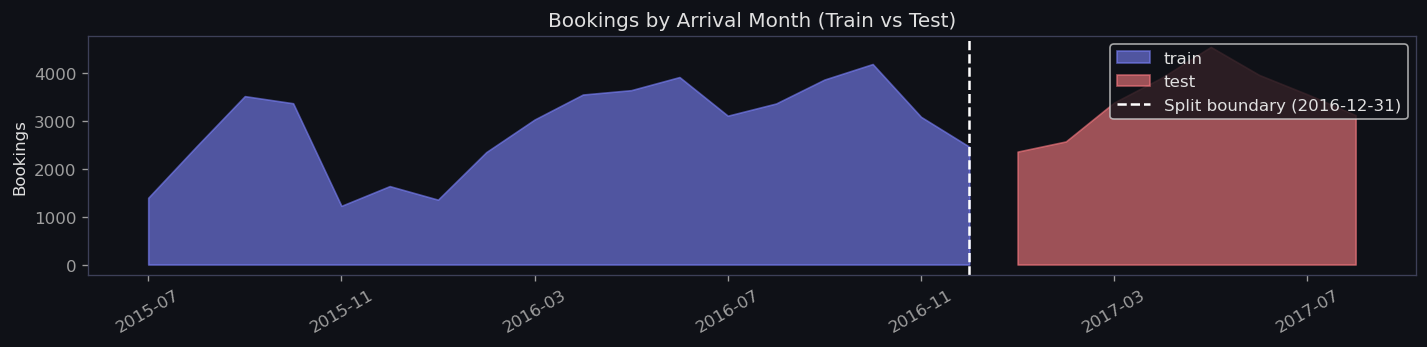

In [5]:
fig, ax = plt.subplots(figsize=(12, 3))
for s, col in zip(['train', 'test'], PAL[:2]):
    sub = df[df.split == s]
    monthly = sub.groupby(sub.arrival_date.dt.to_period('M')).size()
    ax.fill_between(monthly.index.astype(str), monthly.values, alpha=0.6, label=s, color=col)
ax.axvline(str(TRAIN_END.to_period('M')), color='white', linestyle='--', linewidth=1.5,
           label=f'Split boundary ({TRAIN_END.date()})')
ax.set_title('Bookings by Arrival Month (Train vs Test)')
ax.set_ylabel('Bookings')
ax.xaxis.set_major_locator(mticker.MaxNLocator(8))
plt.xticks(rotation=30); plt.legend(); plt.tight_layout(); plt.show()

In [6]:
DROP_ALWAYS = (
    ['booking_id', 'arrival_date', 'booking_date', 'is_canceled', 'split',
     'population', 'is_duplicate', 'gross_value']
    + [c for c in df.columns if c.startswith('syn_')]
    + found_leakage
)

FEATURES     = [c for c in df.columns if c not in DROP_ALWAYS]
CAT_FEATURES = [c for c in FEATURES if df[c].dtype == 'object']
NUM_FEATURES = [c for c in FEATURES if c not in CAT_FEATURES]

print(f'Total features : {len(FEATURES)}')
print(f'  Numeric      : {len(NUM_FEATURES)}')
print(f'  Categorical  : {len(CAT_FEATURES)} {CAT_FEATURES}')

Total features : 52
  Numeric      : 44
  Categorical  : 8 ['market_segment', 'distribution_channel', 'customer_type', 'reserved_room_type', 'meal', 'agent_top', 'arrival_dow', 'deposit_type']


In [7]:
train_df = df[df.split == 'train'].copy()
test_df  = df[df.split == 'test'].copy()

X_train = train_df[FEATURES].copy(); y_train = train_df['is_canceled'].values
X_test  = test_df[FEATURES].copy();  y_test  = test_df['is_canceled'].values

print(f'Train: {len(X_train):,} rows  cancel_rate={y_train.mean():.2%}')
print(f'Test : {len(X_test):,} rows  cancel_rate={y_test.mean():.2%}')

preprocessor = ColumnTransformer([
    ('num', Pipeline([('scaler', StandardScaler())]), NUM_FEATURES),
    ('cat', Pipeline([('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))]), CAT_FEATURES),
], remainder='drop')

# XGBoost does not need scaling
xgb_preprocessor = ColumnTransformer([
    ('num', 'passthrough', NUM_FEATURES),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), CAT_FEATURES),
], remainder='drop')

# Sort train by arrival_date for temporal CV
train_sorted = train_df.sort_values('arrival_date').reset_index(drop=True)
X_tr = train_sorted[FEATURES].copy()
y_tr = train_sorted['is_canceled'].values

N_SPLITS = 5
N_TRIALS = 40
TSCV = TimeSeriesSplit(n_splits=N_SPLITS)
SCORING = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc',
           'precision': 'precision', 'recall': 'recall'}

def cv_summary(name, res):
    return pd.DataFrame([{'model': name, 'metric': k.replace('test_',''),
                          'mean': np.mean(v), 'std': np.std(v)}
                         for k, v in res.items() if k.startswith('test_')])

all_cv = []

Train: 51,496 rows  cancel_rate=41.53%
Test : 27,396 rows  cancel_rate=42.62%


In [8]:
lr_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', LogisticRegression(max_iter=2000, random_state=SEED, class_weight='balanced'))
])
t0 = time.time()
lr_cv = cross_validate(lr_pipe, X_tr, y_tr, cv=TSCV, scoring=SCORING, n_jobs=-1)
print(f'LR CV done in {time.time()-t0:.1f}s')
s = cv_summary('LogReg', lr_cv)
display(s.pivot(index='metric', columns='model', values='mean').round(4))
all_cv.append(s)

lr_pipe.fit(X_tr, y_tr)
print('LogReg trained.')

LR CV done in 9.9s


model,LogReg
metric,
pr_auc,0.8350
precision,0.7330
recall,0.6942
roc_auc,0.8425


LogReg trained.


In [9]:
def rf_objective(trial):
    p = dict(
        n_estimators=trial.suggest_int('n_estimators', 100, 500),
        max_depth=trial.suggest_int('max_depth', 4, 20),
        min_samples_leaf=trial.suggest_int('min_samples_leaf', 5, 50),
        max_features=trial.suggest_float('max_features', 0.2, 1.0),
        class_weight='balanced', random_state=SEED, n_jobs=-1,
    )
    pipe = Pipeline([('pre', preprocessor), ('clf', RandomForestClassifier(**p))])
    s = cross_validate(pipe, X_tr, y_tr, cv=TimeSeriesSplit(3), scoring='average_precision', n_jobs=1)
    return np.mean(s['test_score'])

t0 = time.time()
rf_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
rf_study.optimize(rf_objective, n_trials=N_TRIALS, show_progress_bar=True)
print(f'RF Optuna done {time.time()-t0:.1f}s | Best PR-AUC={rf_study.best_value:.4f}')
print('Best params:', rf_study.best_params)

  0%|          | 0/40 [00:00<?, ?it/s]

RF Optuna done 629.7s | Best PR-AUC=0.8155
Best params: {'n_estimators': 390, 'max_depth': 4, 'min_samples_leaf': 47, 'max_features': 0.3486066014128746}


In [10]:
rf_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', RandomForestClassifier(**rf_study.best_params,
                                   class_weight='balanced', random_state=SEED, n_jobs=-1))
])
rf_cv = cross_validate(rf_pipe, X_tr, y_tr, cv=TSCV, scoring=SCORING, n_jobs=-1)
s = cv_summary('RandomForest', rf_cv)
display(s.pivot(index='metric', columns='model', values='mean').round(4))
all_cv.append(s)

rf_pipe.fit(X_tr, y_tr)
print('RandomForest trained.')

model,RandomForest
metric,
pr_auc,0.8358
precision,0.9841
recall,0.4678
roc_auc,0.8355


RandomForest trained.


In [11]:
SPW = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f'scale_pos_weight = {SPW:.2f}')

def xgb_objective(trial):
    p = dict(
        n_estimators=trial.suggest_int('n_estimators', 200, 1000),
        max_depth=trial.suggest_int('max_depth', 3, 10),
        learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        subsample=trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        min_child_weight=trial.suggest_int('min_child_weight', 1, 20),
        scale_pos_weight=SPW, eval_metric='aucpr', random_state=SEED, verbosity=0,
    )
    pipe = Pipeline([('pre', xgb_preprocessor), ('clf', XGBClassifier(**p))])
    s = cross_validate(pipe, X_tr, y_tr, cv=TimeSeriesSplit(3), scoring='average_precision', n_jobs=1)
    return np.mean(s['test_score'])

t0 = time.time()
xgb_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
xgb_study.optimize(xgb_objective, n_trials=N_TRIALS, show_progress_bar=True)
print(f'XGB Optuna done {time.time()-t0:.1f}s | Best PR-AUC={xgb_study.best_value:.4f}')
print('Best params:', xgb_study.best_params)

scale_pos_weight = 1.41


  0%|          | 0/40 [00:00<?, ?it/s]

XGB Optuna done 471.9s | Best PR-AUC=0.8226
Best params: {'n_estimators': 958, 'max_depth': 3, 'learning_rate': 0.03747968471939845, 'subsample': 0.5057994417050963, 'colsample_bytree': 0.7168721058294292, 'reg_alpha': 3.8282526783010046e-05, 'reg_lambda': 8.73387765182416, 'min_child_weight': 14}


In [12]:
xgb_pipe = Pipeline([
    ('pre', xgb_preprocessor),
    ('clf', XGBClassifier(**xgb_study.best_params,
                          scale_pos_weight=SPW, eval_metric='aucpr',
                          random_state=SEED, verbosity=0))
])
xgb_cv = cross_validate(xgb_pipe, X_tr, y_tr, cv=TSCV, scoring=SCORING, n_jobs=-1)
s = cv_summary('XGBoost', xgb_cv)
display(s.pivot(index='metric', columns='model', values='mean').round(4))
all_cv.append(s)

xgb_pipe.fit(X_tr, y_tr)
print('XGBoost trained.')

model,XGBoost
metric,
pr_auc,0.8551
precision,0.7743
recall,0.7022
roc_auc,0.8561


XGBoost trained.


In [13]:
cv_cmp = pd.concat(all_cv, ignore_index=True)
pivot = (cv_cmp.groupby(['model','metric'])['mean']
         .mean().unstack('metric')[['pr_auc','roc_auc','precision','recall']]
         .sort_values('pr_auc', ascending=False))
print('Cross-Validation Summary (mean over folds)')
display(pivot.round(4))

best_name = pivot.index[0]
print(f'Best model by PR-AUC: {best_name}')

Cross-Validation Summary (mean over folds)


metric,pr_auc,roc_auc,precision,recall
model,,,,
XGBoost,0.8551,0.8561,0.7743,0.7022
RandomForest,0.8358,0.8355,0.9841,0.4678
LogReg,0.8350,0.8425,0.7330,0.6942


Best model by PR-AUC: XGBoost


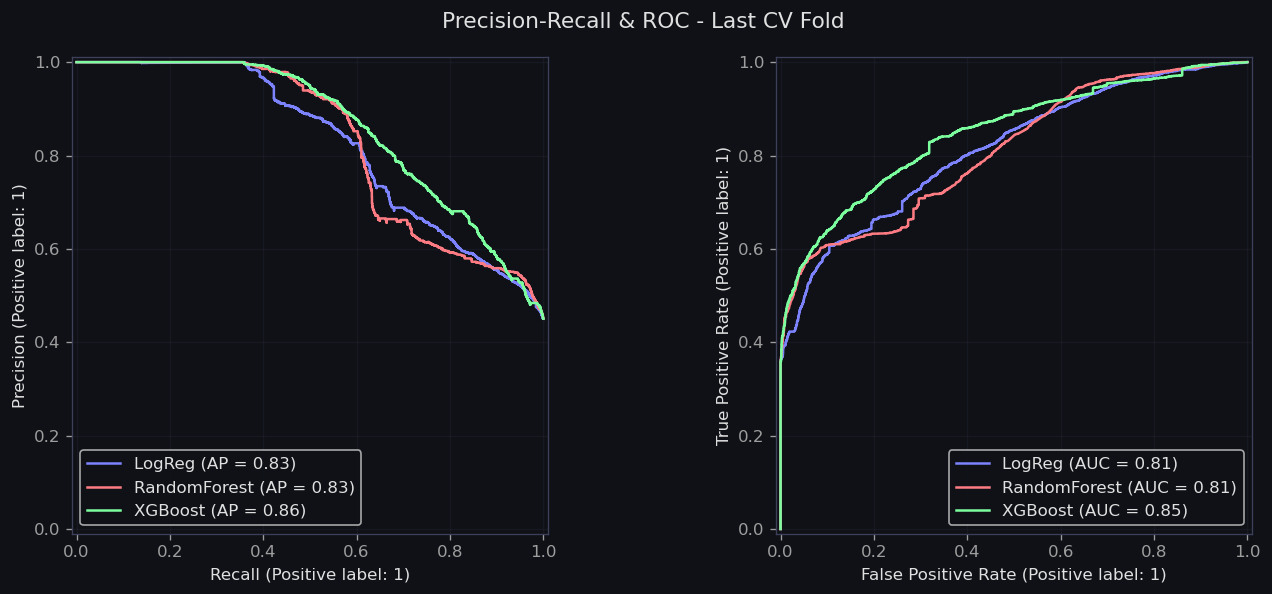

In [14]:
# PR & ROC curves on last CV validation fold
splits_list = list(TSCV.split(X_tr, y_tr))
last_tr_idx, val_idx = splits_list[-1]
X_val, y_val = X_tr.iloc[val_idx], y_tr[val_idx]

models_dict = {'LogReg': lr_pipe, 'RandomForest': rf_pipe, 'XGBoost': xgb_pipe}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Precision-Recall & ROC - Last CV Fold', color='#e0e0e0', fontsize=13)
for (name, mdl), col in zip(models_dict.items(), PAL):
    mdl.fit(X_tr.iloc[last_tr_idx], y_tr[last_tr_idx])
    PrecisionRecallDisplay.from_estimator(mdl, X_val, y_val, ax=axes[0], name=name, color=col)
    RocCurveDisplay.from_estimator(mdl, X_val, y_val, ax=axes[1], name=name, color=col)
for ax in axes:
    ax.set_facecolor('#0f1117'); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

In [15]:
print('Brier Score on validation fold (lower = better):')
for name, mdl in models_dict.items():
    prob = mdl.predict_proba(X_val)[:,1]
    bs   = brier_score_loss(y_val, prob)
    prauc = average_precision_score(y_val, prob)
    print(f'  {name:15s}  Brier={bs:.4f}  PR-AUC={prauc:.4f}')

Brier Score on validation fold (lower = better):
  LogReg           Brier=0.1743  PR-AUC=0.8264
  RandomForest     Brier=0.1709  PR-AUC=0.8298
  XGBoost          Brier=0.1616  PR-AUC=0.8606


In [16]:
BEST_PIPE = models_dict[best_name]
BEST_PIPE.fit(X_tr, y_tr)  # refit on full train set
print(f'{best_name} selected and fitted on full training set.')

XGBoost selected and fitted on full training set.


In [17]:
y_prob = BEST_PIPE.predict_proba(X_test)[:,1]
THRESHOLD = 0.50
y_pred = (y_prob >= THRESHOLD).astype(int)

pr_auc   = average_precision_score(y_test, y_prob)
roc_auc  = roc_auc_score(y_test, y_prob)
brier    = brier_score_loss(y_test, y_prob)
prec     = precision_score(y_test, y_pred, zero_division=0)
rec      = recall_score(y_test, y_pred)

print('='*46)
print(f'  FINAL TEST RESULTS - {best_name}')
print('='*46)
print(f'  PR-AUC    : {pr_auc:.4f}  <- primary metric')
print(f'  ROC-AUC   : {roc_auc:.4f}')
print(f'  Precision : {prec:.4f}  (threshold={THRESHOLD})')
print(f'  Recall    : {rec:.4f}  (threshold={THRESHOLD})')
print(f'  Brier     : {brier:.4f}')
print('='*46)
print()
print(classification_report(y_test, y_pred, target_names=['Stayed','Cancelled']))

  FINAL TEST RESULTS - XGBoost
  PR-AUC    : 0.8300  <- primary metric
  ROC-AUC   : 0.8386
  Precision : 0.7715  (threshold=0.5)
  Recall    : 0.6372  (threshold=0.5)
  Brier     : 0.1593

              precision    recall  f1-score   support

      Stayed       0.76      0.86      0.81     15719
   Cancelled       0.77      0.64      0.70     11677

    accuracy                           0.76     27396
   macro avg       0.77      0.75      0.75     27396
weighted avg       0.77      0.76      0.76     27396



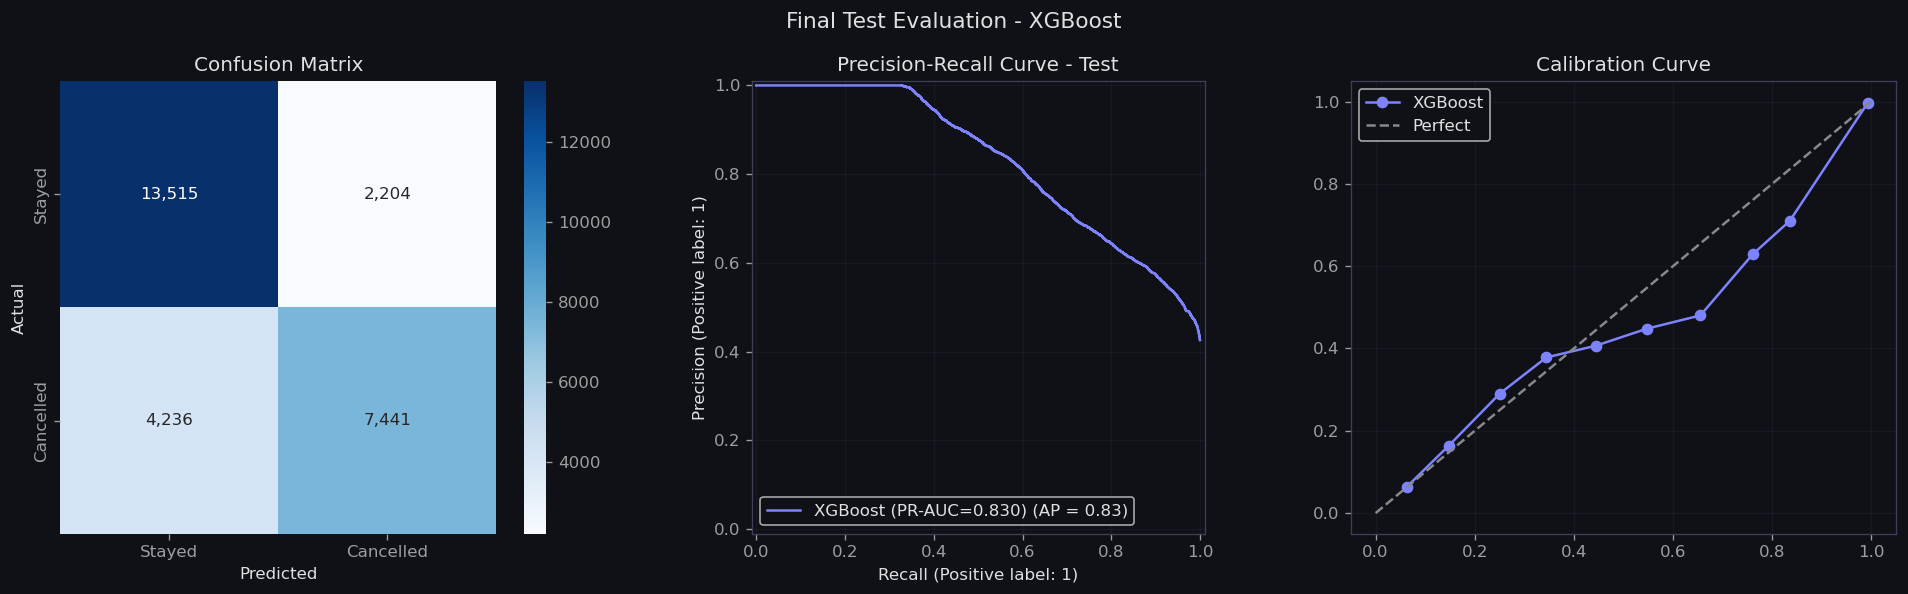

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(f'Final Test Evaluation - {best_name}', color='#e0e0e0', fontsize=13)

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', ax=axes[0],
            xticklabels=['Stayed','Cancelled'], yticklabels=['Stayed','Cancelled'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

PrecisionRecallDisplay.from_estimator(BEST_PIPE, X_test, y_test, ax=axes[1], color=PAL[0],
    name=f'{best_name} (PR-AUC={pr_auc:.3f})')
axes[1].set_title('Precision-Recall Curve - Test')
axes[1].set_facecolor('#0f1117'); axes[1].grid(True, alpha=0.3)

prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)
axes[2].plot(prob_pred, prob_true, 'o-', color=PAL[0], label=best_name)
axes[2].plot([0,1],[0,1],'--',color='#888',label='Perfect')
axes[2].set_title('Calibration Curve'); axes[2].legend()
axes[2].set_facecolor('#0f1117'); axes[2].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

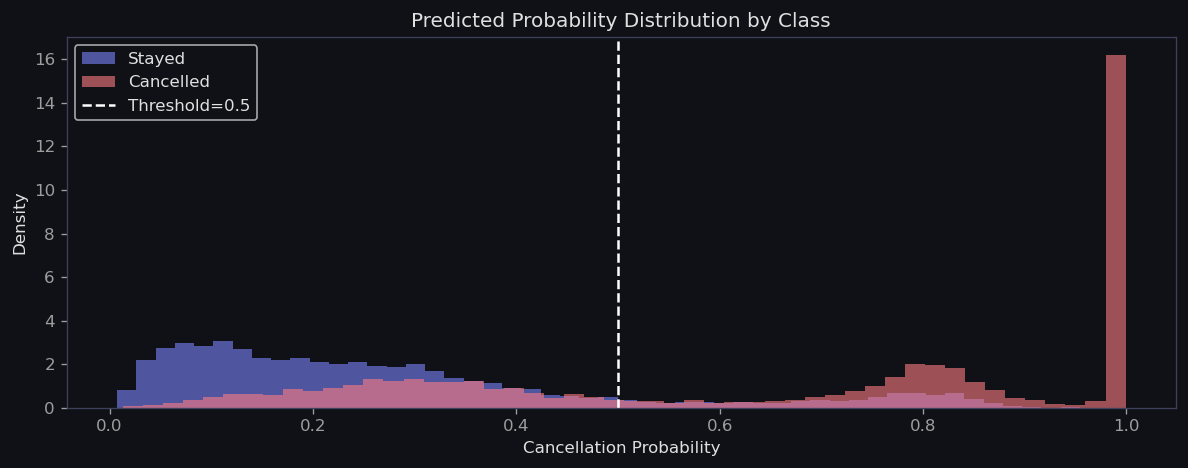

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
for label, col, lbl in zip([0,1], PAL[:2], ['Stayed','Cancelled']):
    ax.hist(y_prob[y_test==label], bins=50, alpha=0.6, color=col, label=lbl, density=True)
ax.axvline(THRESHOLD, color='white', linestyle='--', linewidth=1.5, label=f'Threshold={THRESHOLD}')
ax.set_title('Predicted Probability Distribution by Class')
ax.set_xlabel('Cancellation Probability'); ax.set_ylabel('Density')
ax.legend(); plt.tight_layout(); plt.show()

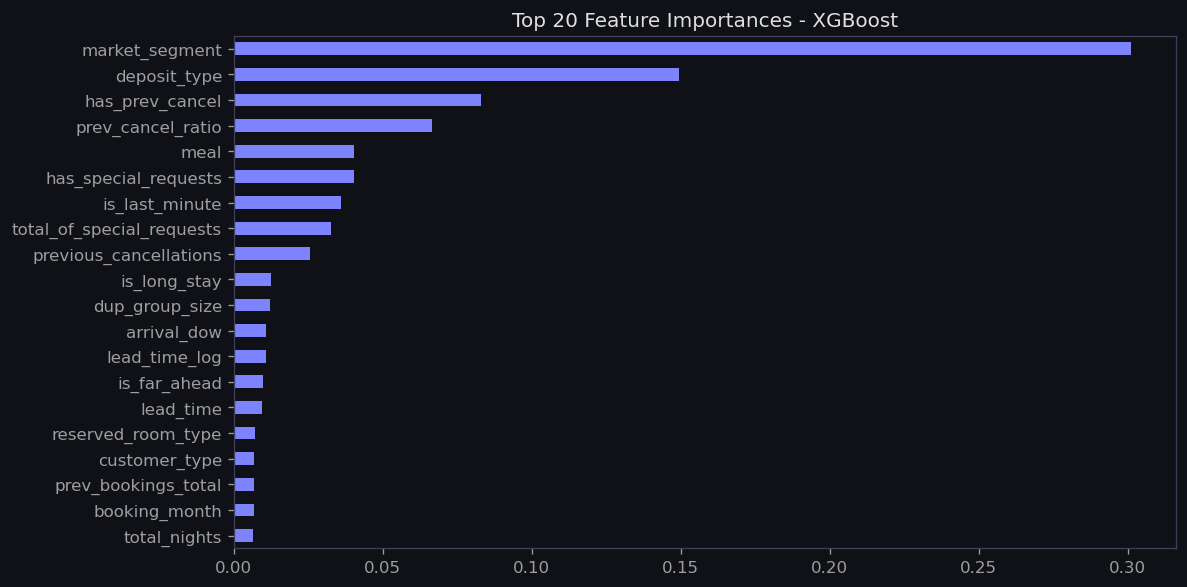

In [20]:
clf = BEST_PIPE.named_steps['clf']
if hasattr(clf, 'feature_importances_'):
    fi = pd.Series(clf.feature_importances_, index=FEATURES).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(10,5))
    fi.head(20).plot.barh(ax=ax, color=PAL[0])
    ax.invert_yaxis()
    ax.set_title(f'Top 20 Feature Importances - {best_name}')
    plt.tight_layout(); plt.show()
elif hasattr(clf, 'coef_'):
    coef = pd.Series(np.abs(clf.coef_[0]), index=FEATURES).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(10,5))
    coef.head(20).plot.barh(ax=ax, color=PAL[1])
    ax.invert_yaxis()
    ax.set_title('Top 20 |Coefficients| - LogReg')
    plt.tight_layout(); plt.show()

## Step 7 · Cancellation Risk Output

In [21]:
X_all = df[FEATURES].copy()
prob_all = BEST_PIPE.predict_proba(X_all)[:,1]

risk_df = df[['booking_id','arrival_date','booking_date','split','population',
               'is_canceled','market_segment','distribution_channel',
               'customer_type','deposit_type','lead_time','total_nights','adr_clean']].copy()

risk_df['cancel_prob'] = prob_all.round(4)
risk_df['risk_label']  = pd.cut(risk_df.cancel_prob, bins=[-0.001,0.30,0.60,1.001],
                                labels=['Low','Medium','High'])
risk_df['predicted_cancel'] = (risk_df.cancel_prob >= THRESHOLD).astype(int)

print('Risk score distribution:')
print(risk_df.risk_label.value_counts())
display(risk_df.head(5))

Risk score distribution:
risk_label
Low       37798
High      26396
Medium    14698
Name: count, dtype: int64


,booking_id,arrival_date,booking_date,split,population,is_canceled,market_segment,distribution_channel,customer_type,deposit_type,lead_time,total_nights,adr_clean,cancel_prob,risk_label,predicted_cancel
0,1,2015-07-01,2015-06-25,train,individual,0,Offline TA/TO,TA/TO,Transient,No Deposit,6,2,0.0,0.1167,Low,0
1,2,2015-07-01,2015-04-04,train,individual,1,Online TA,TA/TO,Transient,No Deposit,88,4,76.5,0.4158,Medium,0
2,3,2015-07-01,2015-04-27,train,individual,1,Online TA,TA/TO,Transient,No Deposit,65,4,68.0,0.3339,Medium,0
3,4,2015-07-01,2015-03-31,train,individual,1,Online TA,TA/TO,Transient,No Deposit,92,6,76.5,0.4261,Medium,0
4,5,2015-07-02,2015-03-24,train,individual,1,Online TA,TA/TO,Transient,No Deposit,100,2,76.5,0.5142,Medium,1


In [22]:
out_file = OUT / 'cancellation_risk_scores.csv'
risk_df.to_csv(out_file, index=False)
print(f'Risk scores saved -> {out_file}  ({len(risk_df):,} rows)')

Risk scores saved -> ..\data\outputs\cancellation_risk_scores.csv  (78,892 rows)


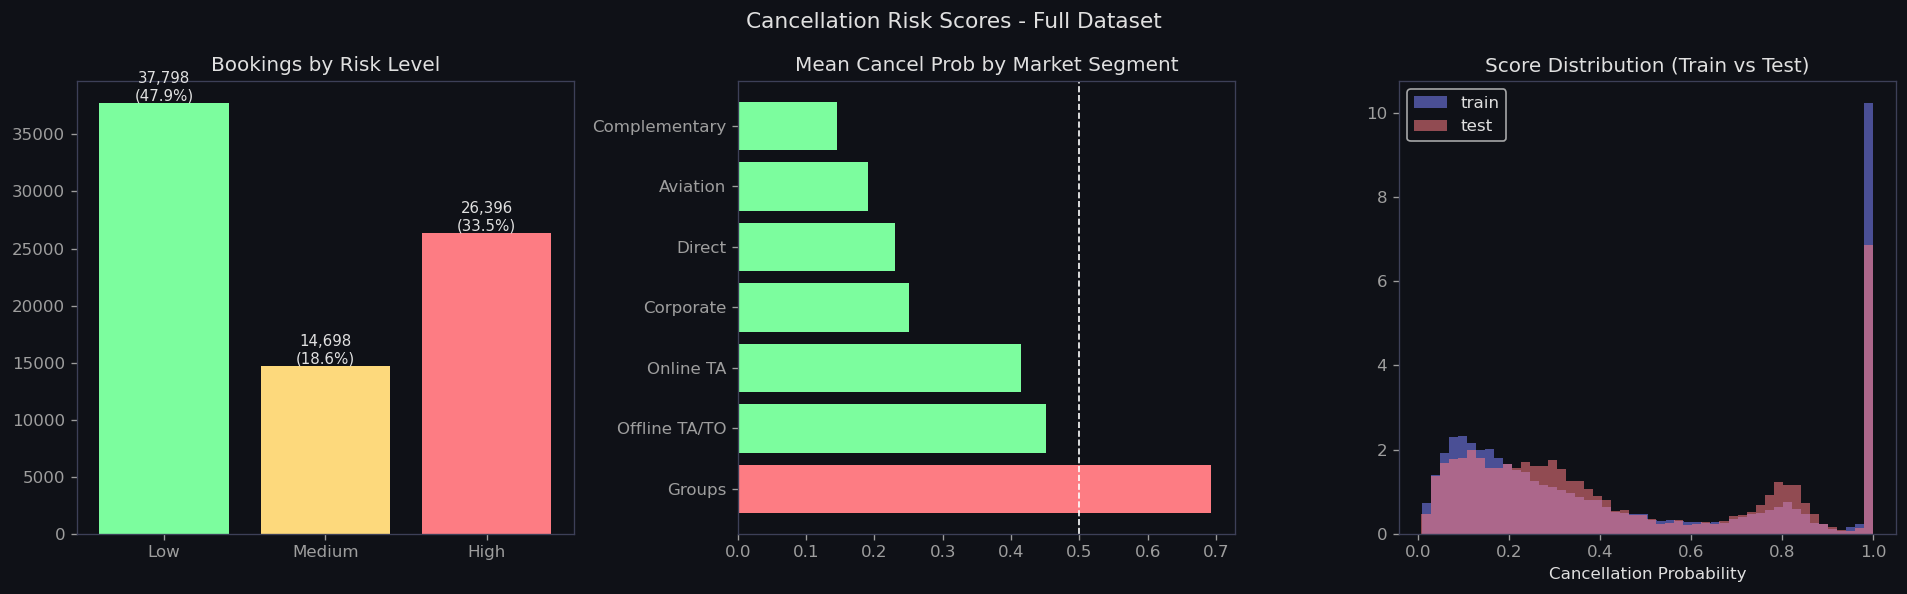

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Cancellation Risk Scores - Full Dataset', color='#e0e0e0', fontsize=13)

risk_vc = risk_df.risk_label.value_counts().reindex(['Low','Medium','High'])
colors_risk = [PAL[2], PAL[3], PAL[1]]
axes[0].bar(risk_vc.index, risk_vc.values, color=colors_risk)
axes[0].set_title('Bookings by Risk Level')
for i, v in enumerate(risk_vc.values):
    axes[0].text(i, v+200, f'{v:,}\n({v/len(risk_df):.1%})', ha='center', fontsize=9)

seg_risk = risk_df.groupby('market_segment')['cancel_prob'].mean().sort_values(ascending=False)
colors_seg = [PAL[1] if v>0.5 else PAL[2] for v in seg_risk.values]
axes[1].barh(seg_risk.index, seg_risk.values, color=colors_seg)
axes[1].set_title('Mean Cancel Prob by Market Segment')
axes[1].axvline(0.5, color='white', linestyle='--', linewidth=1)

for s, col in zip(['train','test'], PAL[:2]):
    sub = risk_df[risk_df.split==s]
    axes[2].hist(sub.cancel_prob, bins=50, alpha=0.55, color=col, label=s, density=True)
axes[2].set_title('Score Distribution (Train vs Test)')
axes[2].set_xlabel('Cancellation Probability')
axes[2].legend()

plt.tight_layout(); plt.show()

In [24]:
model_path = OUT / f'best_model_{best_name.lower().replace(" ","_")}.pkl'
joblib.dump(BEST_PIPE, model_path)
print(f'Model saved -> {model_path}')

summary = dict(
    model=best_name, threshold=THRESHOLD,
    test_pr_auc=round(pr_auc,4), test_roc_auc=round(roc_auc,4),
    test_precision=round(prec,4), test_recall=round(rec,4), test_brier=round(brier,4),
    features=FEATURES, n_train=int(len(X_train)), n_test=int(len(X_test)),
)
(OUT / 'model_summary.json').write_text(json.dumps(summary, indent=2))
print(f'Summary saved -> {OUT}/model_summary.json')

print()
print('Output files:')
print(f'  data/outputs/cancellation_risk_scores.csv  -- cancel_prob per booking')
print(f'  data/outputs/{model_path.name}  -- trained model pipeline')
print(f'  data/outputs/model_summary.json            -- metrics & config')

Model saved -> ..\data\outputs\best_model_xgboost.pkl
Summary saved -> ..\data\outputs/model_summary.json

Output files:
  data/outputs/cancellation_risk_scores.csv  -- cancel_prob per booking
  data/outputs/best_model_xgboost.pkl  -- trained model pipeline
  data/outputs/model_summary.json            -- metrics & config


## Step 8 · Ablation

Tách ảnh hưởng của (1) population `individual` vs toàn bộ, (2) nhóm feature nghi ngờ leak/snapshot (ADR, deposit, group, ...). Đọc `lift` và `roc_auc`, không so PR-AUC thô giữa các dòng.

In [25]:
import json
import numpy as np, pandas as pd
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier

PARAMS = dict(xgb_study.best_params, eval_metric='aucpr', random_state=42, verbosity=0)

def run(sub, feats, label):
    tr, te = sub[sub.split == 'train'], sub[sub.split == 'test']
    cat = [c for c in feats if sub[c].dtype == 'object']
    num = [c for c in feats if c not in cat]
    pre = ColumnTransformer([('n', 'passthrough', num),
                             ('c', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat)])
    spw = (tr.is_canceled == 0).sum() / (tr.is_canceled == 1).sum()
    m = Pipeline([('pre', pre), ('clf', XGBClassifier(**PARAMS, scale_pos_weight=spw))])
    m.fit(tr[feats], tr.is_canceled)
    p = m.predict_proba(te[feats])[:, 1]
    base = te.is_canceled.mean()
    ap = average_precision_score(te.is_canceled, p)
    return dict(scenario=label, n_train=len(tr), n_test=len(te), n_feat=len(feats),
                event_rate=round(base, 3), pr_auc=round(ap, 4), lift=round(ap / base, 3),
                roc_auc=round(roc_auc_score(te.is_canceled, p), 4))

# --- nhóm feature nghi ngờ (snapshot / gần như leak) ---
GROUPS = {
    'adr':      ['adr_clean', 'adr_vs_ref', 'adr_per_guest', 'is_free_rate'],
    'deposit':  ['deposit_type', 'is_non_refund'],
    'group':    ['is_group_block', 'dup_group_size', 'dup_group_size_log'],
    'otb':      ['drv_otb_rooms_at_booking'],
    'previous': ['previous_cancellations', 'previous_bookings_not_canceled',
                 'prev_bookings_total', 'prev_cancel_ratio', 'has_prev_cancel', 'is_repeated_guest'],
    'special':  ['total_of_special_requests', 'has_special_requests',
                 'days_in_waiting_list', 'has_waiting_list'],
}
drop = lambda cols: [f for f in FEATURES if f not in cols]

# --- feature list của notebook 04 (nếu có config) ---
B_FEATS = None
cfg = Path('column_groups.json')           # upload file config/column_groups.json lên Colab nếu muốn dùng đúng
if cfg.exists():
    ic = json.loads(cfg.read_text(encoding='utf-8'))['individual_model']
    excl = set(ic['pre_arrival_extra']) | {'adr_clean', 'adr_vs_ref', 'adr_per_guest'}
    B_FEATS = [c for c in ic['numeric'] + ic['categorical'] if c not in excl and c in df.columns]

ind = df[df.population == 'individual']
rows = []

# 1) Tách nguyên nhân chính
rows.append(run(df,  FEATURES, 'A gốc: all population + 52 feat'))
rows.append(run(ind, FEATURES, 'chỉ individual + 52 feat'))
if B_FEATS:
    rows.append(run(df,  B_FEATS, 'all population + feat của B'))
    rows.append(run(ind, B_FEATS, 'individual + feat của B (~ notebook 04)'))

# 2) Leave-one-group-out trên individual: nhóm nào kéo điểm lên?
for g, cols in GROUPS.items():
    rows.append(run(ind, drop(cols), f'individual - bỏ nhóm {g}'))
rows.append(run(ind, drop(sum(GROUPS.values(), [])), 'individual - bỏ TẤT CẢ nhóm nghi ngờ'))

res = pd.DataFrame(rows)
display(res)


,scenario,n_train,n_test,n_feat,event_rate,pr_auc,lift,roc_auc
0,A gốc: all population + 52 feat,51496,27396,52,0.426,0.8303,1.948,0.8396
1,chỉ individual + 52 feat,32277,20399,52,0.344,0.6105,1.776,0.7529
2,individual - bỏ nhóm adr,32277,20399,48,0.344,0.6062,1.764,0.7536
3,individual - bỏ nhóm deposit,32277,20399,50,0.344,0.6097,1.774,0.7534
4,individual - bỏ nhóm group,32277,20399,49,0.344,0.6071,1.766,0.7547
5,individual - bỏ nhóm otb,32277,20399,51,0.344,0.6062,1.764,0.7517
6,individual - bỏ nhóm previous,32277,20399,46,0.344,0.6153,1.790,0.7544
7,individual - bỏ nhóm special,32277,20399,48,0.344,0.5430,1.580,0.7298
8,individual - bỏ TẤT CẢ nhóm nghi ngờ,32277,20399,32,0.344,0.5410,1.574,0.7252
